* load và ktra lại

In [13]:
# =====================================
# PACKAGE 3 - LOAD DATA & BASELINE MODELS
# =====================================

import pandas as pd
import numpy as np
import joblib

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    f1_score,
    precision_score,
    recall_score
)

# =====================================
# LOAD DATASET
# =====================================

df = pd.read_csv(
    r"E:\Banking_AI\data\data_process\creditcard_processed.csv"
)

# split giống package_2
X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# =====================================
# LOAD BASELINE MODELS
# =====================================

rf = joblib.load(
    r"E:\Banking_AI\data\data_process\model_train_package 2\rf_baseline.pkl"
)

xgb = joblib.load(
    r"E:\Banking_AI\data\data_process\model_train_package 2\xgb_baseline.pkl"
)

# =====================================
# LOAD PACKAGE 2 RESULTS
# =====================================

baseline_results = pd.read_csv(
    r"E:\Banking_AI\data\data_process\model_train_package 2\baseline_results.csv"
)

print("="*50)
print("PACKAGE 3 READY")
print("="*50)

print("\nDataset Shape:")
print(df.shape)

print("\nBaseline Results:")
display(baseline_results)

print("\nRandom Forest Loaded ✅")
print("\nXGBoost Loaded ✅")

PACKAGE 3 READY

Dataset Shape:
(284807, 31)

Baseline Results:


,Model,Precision,Recall,F1
0,LogisticRegression,0.70,0.85,0.76
1,RandomForest,0.92,0.81,0.86
2,XGBoost,0.87,0.84,0.85



Random Forest Loaded ✅

XGBoost Loaded ✅


In [14]:
print("Random Forest")

print(
    classification_report(
        y_test,
        rf.predict(X_test)
    )
)

print("\nXGBoost")

print(
    classification_report(
        y_test,
        xgb.predict(X_test)
    )
)

Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.92      0.81      0.86        98

    accuracy                           1.00     56962
   macro avg       0.96      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962


XGBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.87      0.84      0.85        98

    accuracy                           1.00     56962
   macro avg       0.94      0.92      0.93     56962
weighted avg       1.00      1.00      1.00     56962



Cross Validation

In [15]:
#tạo cv (cross validation) để đánh giá mô hình
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [16]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    xgb,
    X,
    y,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)


In [17]:
print(scores)
print(scores.mean())
print(scores.std())

[0.85263158 0.90322581 0.88297872 0.85245902 0.84210526]
0.8666800776709149
0.02282435783738825


* create space search

In [18]:
param_grid = {
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300]
}

print(param_grid)

{'max_depth': [4, 6, 8], 'learning_rate': [0.01, 0.05, 0.1], 'n_estimators': [100, 200, 300]}


1. tại sao chọn grid vì trong bài toán này chỉ có 27 tổ hợp nên grid sẽ khả thi hơn, còn trên 50 thì ưu tiên RandomizedSearchCV sẽ oke hơn

In [24]:
scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)
print(scale_pos_weight)

577.2868020304569


In [23]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

xgb_tune = XGBClassifier(
    tree_method="hist",
    device="cuda",
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

In [29]:
grid = GridSearchCV(
    estimator=xgb_tune,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 27 candidates, totalling 135 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.05, ...], 'max_depth': [4, 6, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_exa

In [30]:
print("Best Score:")
print(grid.best_score_)

print("\nBest Params:")
print(grid.best_params_)

Best Score:
0.8572121034932836

Best Params:
{'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300}


In [31]:
best_xgb = grid.best_estimator_

print(best_xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device='cuda', early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, ...)


In [32]:
best_xgb = grid.best_estimator_

In [33]:
best_pred = best_xgb.predict(X_test)

print(
    classification_report(
        y_test,
        best_pred
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.87      0.85      0.86        98

    accuracy                           1.00     56962
   macro avg       0.94      0.92      0.93     56962
weighted avg       1.00      1.00      1.00     56962



In [34]:
results = pd.DataFrame(
    grid.cv_results_
)

results[
    [
        "mean_test_score",
        "param_max_depth",
        "param_learning_rate",
        "param_n_estimators"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
).head(10)

,mean_test_score,param_max_depth,param_learning_rate,param_n_estimators
23,0.857212,6,0.10,300
22,0.855268,6,0.10,200
26,0.854580,8,0.10,300
25,0.852026,8,0.10,200
14,0.846283,6,0.05,300
20,0.844172,4,0.10,300
24,0.840890,8,0.10,100
17,0.840623,8,0.05,300
16,0.839005,8,0.05,200
13,0.807457,6,0.05,200


## Section 3: Threshold Optimization

Lấy probability

In [36]:
best_xgb = grid.best_estimator_

probs = best_xgb.predict_proba(X_test)[:,1]

print(probs[:20])

[1.4193595e-06 3.4133376e-07 5.6543308e-06 3.2933710e-07 1.6241098e-05
 6.2394150e-07 3.5600527e-07 1.3116791e-07 3.2190151e-06 4.3054706e-07
 7.0673245e-06 2.1156884e-05 3.5267610e-06 2.4848080e-07 1.7191828e-06
 6.6294001e-07 5.2231235e-06 5.7501512e-07 4.3377366e-07 8.4452167e-06]


Tạo dải threshold

In [40]:
thresholds = np.arange(
    0.05,
    1.00,
    0.05
)

print(thresholds)

[0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7
 0.75 0.8  0.85 0.9  0.95]


Tính F1 theo từng threshold

In [44]:
from sklearn.metrics import f1_score

f1_scores = []

for threshold in thresholds:

    preds = (
        probs > threshold
    ).astype(int)

    f1 = f1_score(
        y_test,
        preds
    )

    f1_scores.append(f1)
    
print( f1_scores)

[0.8076923076923077, 0.83, 0.8426395939086294, 0.8512820512820513, 0.8556701030927835, 0.8601036269430051, 0.8601036269430051, 0.8601036269430051, 0.8601036269430051, 0.8601036269430051, 0.8601036269430051, 0.8601036269430051, 0.8541666666666666, 0.8541666666666666, 0.8481675392670157, 0.8617021276595744, 0.8663101604278075, 0.8709677419354839, 0.8743169398907104]


draw biểu đồ

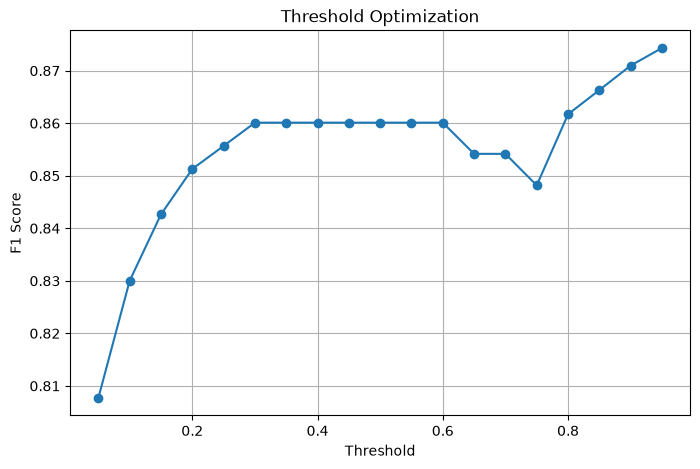

In [45]:
plt.figure(figsize=(8,5))

plt.plot(
    thresholds,
    f1_scores,
    marker='o'
)

plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("Threshold Optimization")

plt.grid(True)

plt.show()

In [46]:
best_idx = np.argmax(f1_scores)

print(
    "Best Threshold:",
    thresholds[best_idx]
)

print(
    "Best F1:",
    f1_scores[best_idx]
)

Best Threshold: 0.9500000000000001
Best F1: 0.8743169398907104


In [47]:
best_threshold = thresholds[best_idx]

preds_95 = (
    probs > best_threshold
).astype(int)

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        preds_95
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



Threshold tuning cho thấy ngưỡng mặc định 0.5 không phải lựa chọn tối ưu. Khi tăng threshold lên 0.95, Precision tăng từ 0.87 lên 0.94 trong khi Recall chỉ giảm từ 0.85 xuống 0.82. Điều này giúp cải thiện F1-score lên 0.87.

save


In [49]:
import joblib

joblib.dump(
    best_xgb,
    r"E:\Banking_AI\data\data_process\model_train_package_3\best_xgb_tuned.pkl"
)


['E:\\Banking_AI\\data\\data_process\\model_train_package_3\\best_xgb_tuned.pkl']

In [50]:
import json

threshold_info = {
    "best_threshold": 0.95,
    "precision": 0.94,
    "recall": 0.82,
    "f1": 0.87
}

with open(
    r"E:\Banking_AI\data\data_process\model_train_package_3\best_threshold.json",
    "w"
) as f:
    json.dump(
        threshold_info,
        f,
        indent=4
    )

In [51]:
grid_results = pd.DataFrame(
    grid.cv_results_
)

grid_results.to_csv(
    r"E:\Banking_AI\data\data_process\model_train_package_3\grid_results.csv",
    index=False
)

In [52]:
final_results = pd.DataFrame({
    "Model":["XGBoost Final"],
    "Precision":[0.94],
    "Recall":[0.82],
    "F1":[0.87],
    "Threshold":[0.95]
})


In [53]:
final_results.to_csv(
    r"E:\Banking_AI\data\data_process\model_train_package_3\final_results.csv",
    index=False
)